# stOTopic synthetic quickstart

Synthetic counts have three synthetic regions. Gene and region labels have no biological meaning; this tutorial demonstrates installation and software outputs.

Install stOTopic and follow [data setup](README.md) before running.

## 1. Input

In [1]:
from pathlib import Path
import os
import anndata as ad
import pandas as pd
import torch
from IPython.display import display, Image
from stotopic import stOTopic, pp
from stotopic.demo import export_results, make_demo_data

ROOT = Path.cwd()
if ROOT.name == "tutorials":
    ROOT = ROOT.parent
os.chdir(ROOT)
torch.set_num_threads(1)
torch.set_float32_matmul_precision("high")
torch.backends.cuda.matmul.allow_tf32 = True
device = "cuda" if torch.cuda.is_available() else "cpu"


In [2]:
raw = make_demo_data()
output = Path("outputs/quickstart")
cell_type_key = "synthetic_region"
print("Synthetic counts:", raw.shape)


Synthetic counts: (180, 90)


## 2. Prepare spatial representations

Counts remain unchanged for fitting. A separate normalized representation is propagated with SGCN and reduced by PCA.

In [3]:
parameters = {
    "num_topics": 20, "n_components": 400, "gene_selection": "all",
    "use_sgc": True, "sgc_mode": "sign", "sgc_layers": 1,
    "ct_alpha": 10.0, "tg_alpha": 1.0, "learning_rate": 0.01,
    "theta_temp": 0.1, "epochs": 10000, "early_stop_threshold": 0.1,
    "patience": 5, "seed": None, "device": device,
}
selected, embeddings = pp.prepare(
    raw, gene_selection="all", n_components=400, min_counts=50,
    use_sgc=True, sgc_layers=1, sgc_mode="sign", random_state=None,
)
print("Prepared counts:", selected.shape)


Prepared counts: (180, 90)


## 3. Fit and export model outputs

In [4]:
model = stOTopic(20, CT_alpha=10.0, TG_alpha=1.0, theta_temp=0.1, device=device)
theta = model.fit_transform(
    selected, cell_embeddings=embeddings, use_highly_variable=False,
    epochs=10000, learning_rate=0.01, early_stop_threshold=0.1, patience=5,
)
result = export_results(
    selected, model, theta, output, cell_type_key=cell_type_key,
    focus_cell_type="Tumor", parameters=parameters,
)
print("theta (cells x topics):", result["theta"].shape)
print("beta (genes x topics):", result["beta"].shape)
display(result["theta"].iloc[:5, :5])
display(result["beta"].iloc[:5, :5])


theta (cells x topics): (180, 20)
beta (genes x topics): (90, 20)


,Topic1,Topic2,Topic3,Topic4,Topic5
cell_0,0.239823,0.000544,0.004270,0.016241,0.017636
cell_1,0.014092,0.001398,0.000492,0.011844,0.009639
cell_2,0.196091,0.000109,0.000121,0.009475,0.029818
cell_3,0.058320,0.000371,0.001239,0.026502,0.074576
cell_4,0.596542,0.003611,0.000108,0.012993,0.029085


,Topic1,Topic2,Topic3,Topic4,Topic5
gene_0,0.021918,0.001028,0.000008,0.018973,0.032470
gene_1,0.034353,0.000642,0.000004,0.040632,0.031193
gene_2,0.035232,0.000737,0.000006,0.024818,0.026167
gene_3,0.032936,0.000743,0.000005,0.023444,0.017274
gene_4,0.025757,0.000625,0.000005,0.023047,0.015871


## 4. Representative genes

All topics have a ranked gene table. The figure shows up to six selected topics; program candidates are included when supported.

,top_genes
topic,
Topic1,"[gene_16, gene_10, gene_18, gene_25, gene_15, gene_2, gene_20, gene_1, gene_13, gene_3]"
Topic2,"[gene_45, gene_46, gene_41, gene_49, gene_57, gene_53, gene_50, gene_36, gene_47, gene_34]"
Topic3,"[gene_76, gene_82, gene_81, gene_77, gene_85, gene_70, gene_80, gene_63, gene_87, gene_83]"
Topic4,"[gene_7, gene_28, gene_12, gene_10, gene_1, gene_29, gene_16, gene_15, gene_8, gene_14]"
Topic5,"[gene_15, gene_6, gene_0, gene_1, gene_8, gene_18, gene_9, gene_25, gene_22, gene_26]"
Topic6,"[gene_35, gene_55, gene_54, gene_59, gene_43, gene_48, gene_58, gene_47, gene_53, gene_38]"
Topic7,"[gene_85, gene_65, gene_75, gene_67, gene_88, gene_77, gene_82, gene_78, gene_62, gene_80]"
Topic8,"[gene_27, gene_20, gene_4, gene_7, gene_9, gene_19, gene_5, gene_25, gene_21, gene_23]"
Topic9,"[gene_60, gene_62, gene_87, gene_85, gene_71, gene_61, gene_84, gene_79, gene_69, gene_74]"


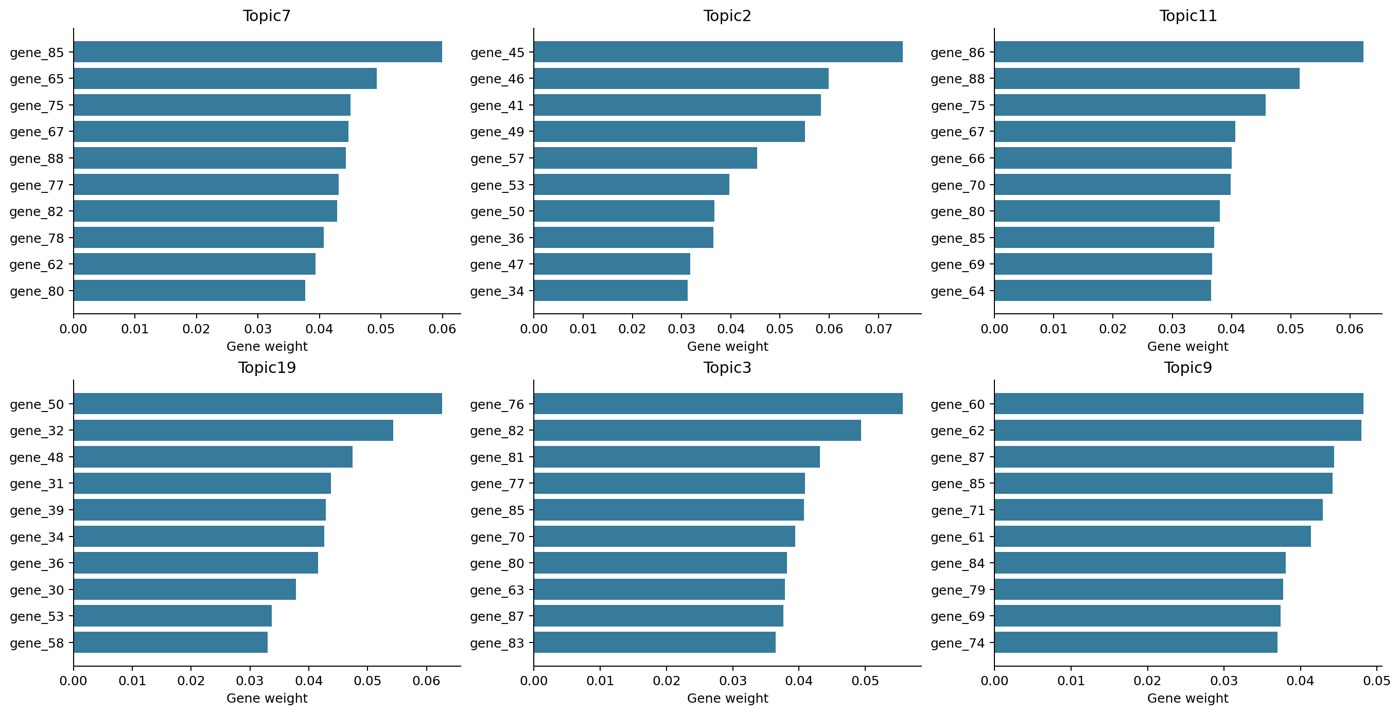

In [5]:
def show_panel(name):
    path = output / "figures" / (name + ".png")
    if "figures/" + name + ".png" in result["run_config"]["figures"]:
        display(Image(filename=str(path), width=1000))
    else:
        print("Panel unavailable for this run:", name)
display(result["top_genes"].groupby("topic", sort=False)["gene"].apply(list).to_frame("top_genes"))
show_panel("topic_genes")


## 5. Topic weights

Mean topic proportions summarize program contribution across cells. They are not cell-type abundance estimates.

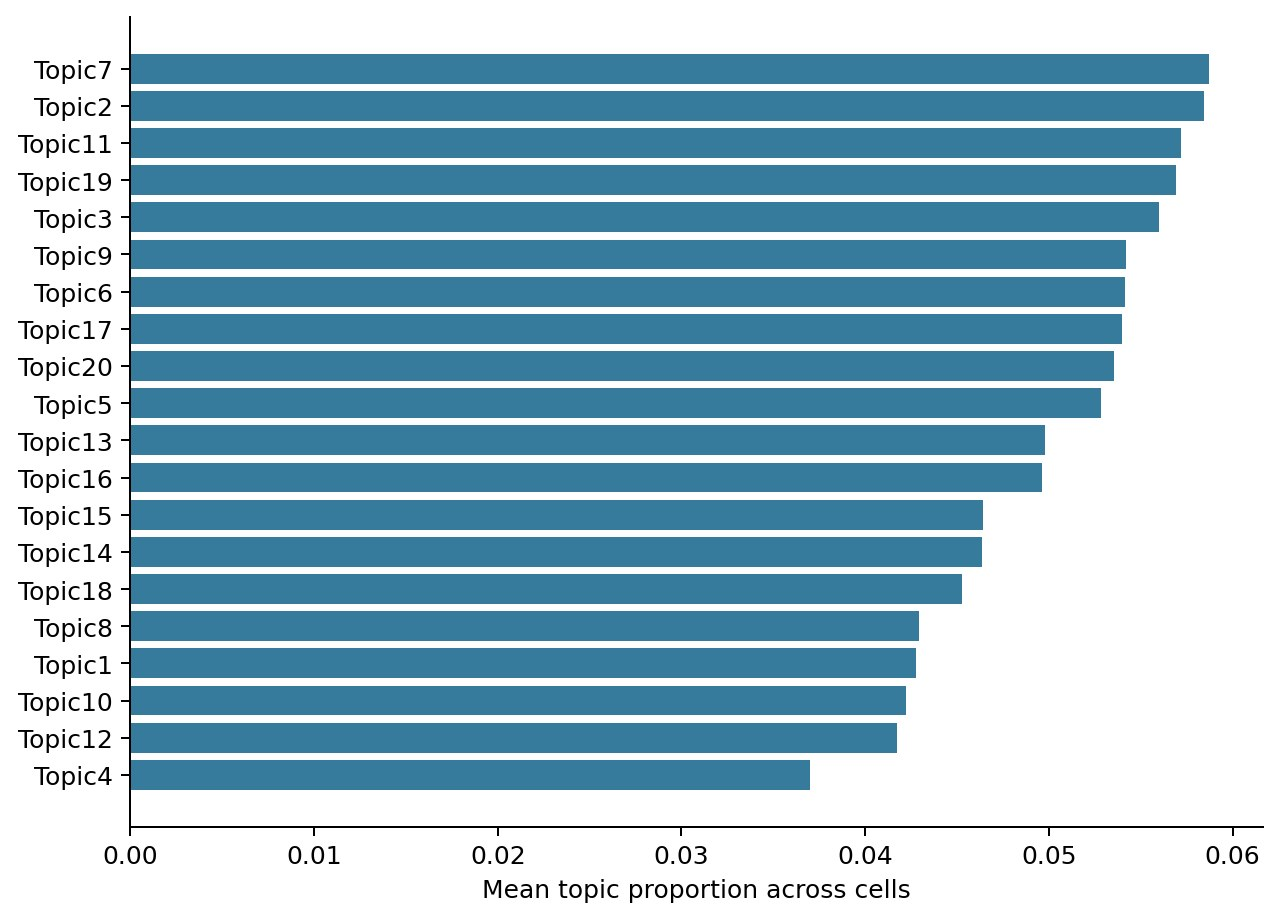

In [6]:
show_panel("topic_weights")


## 6. Spatial topics and original annotations

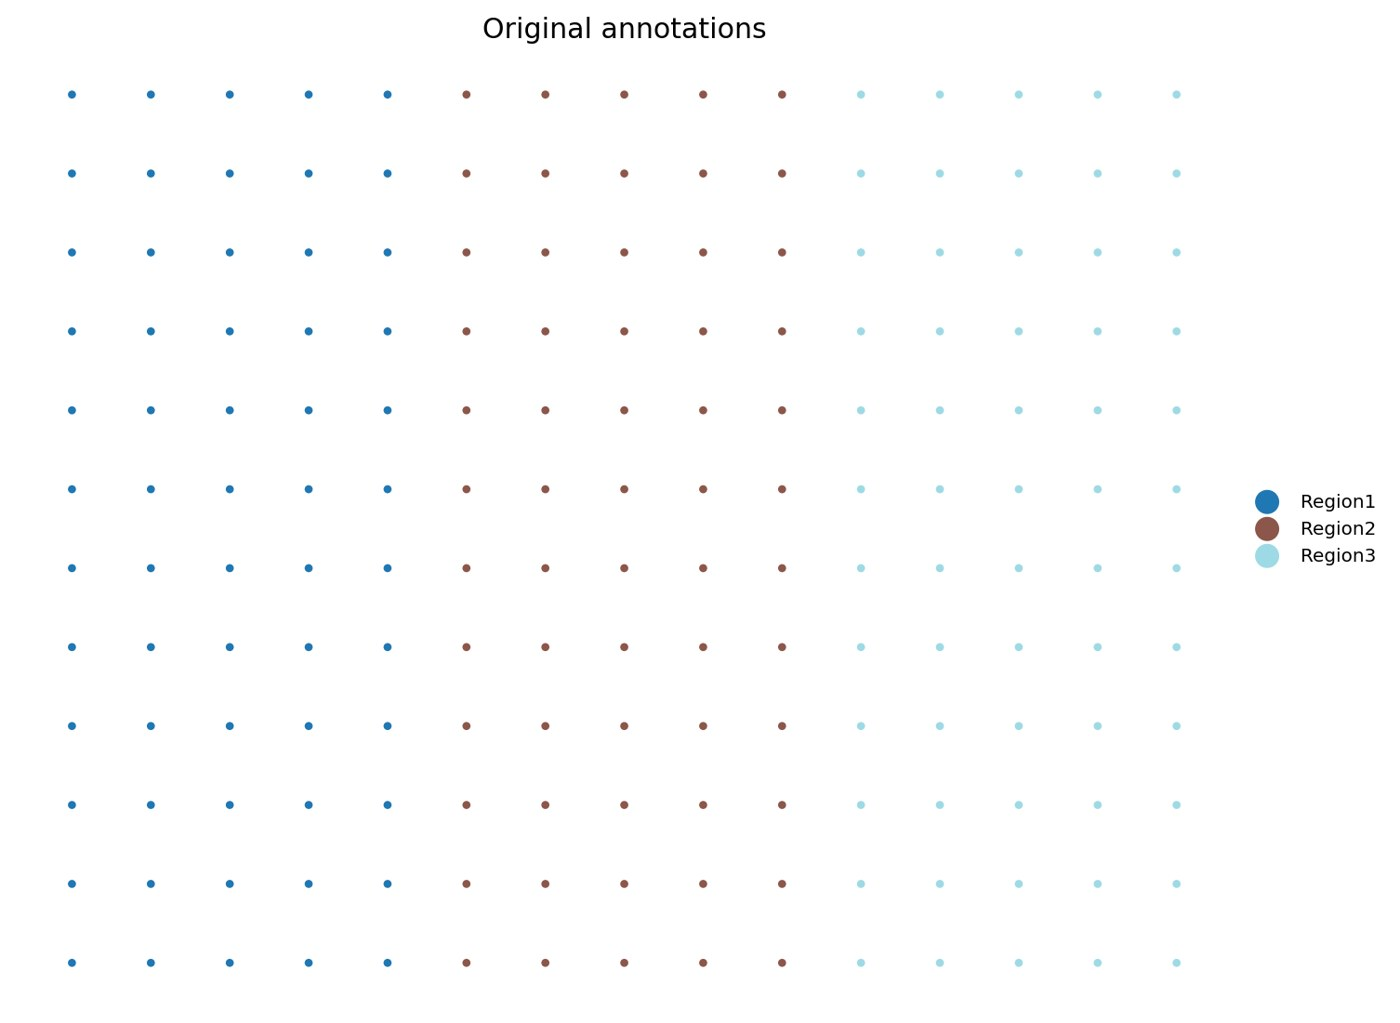

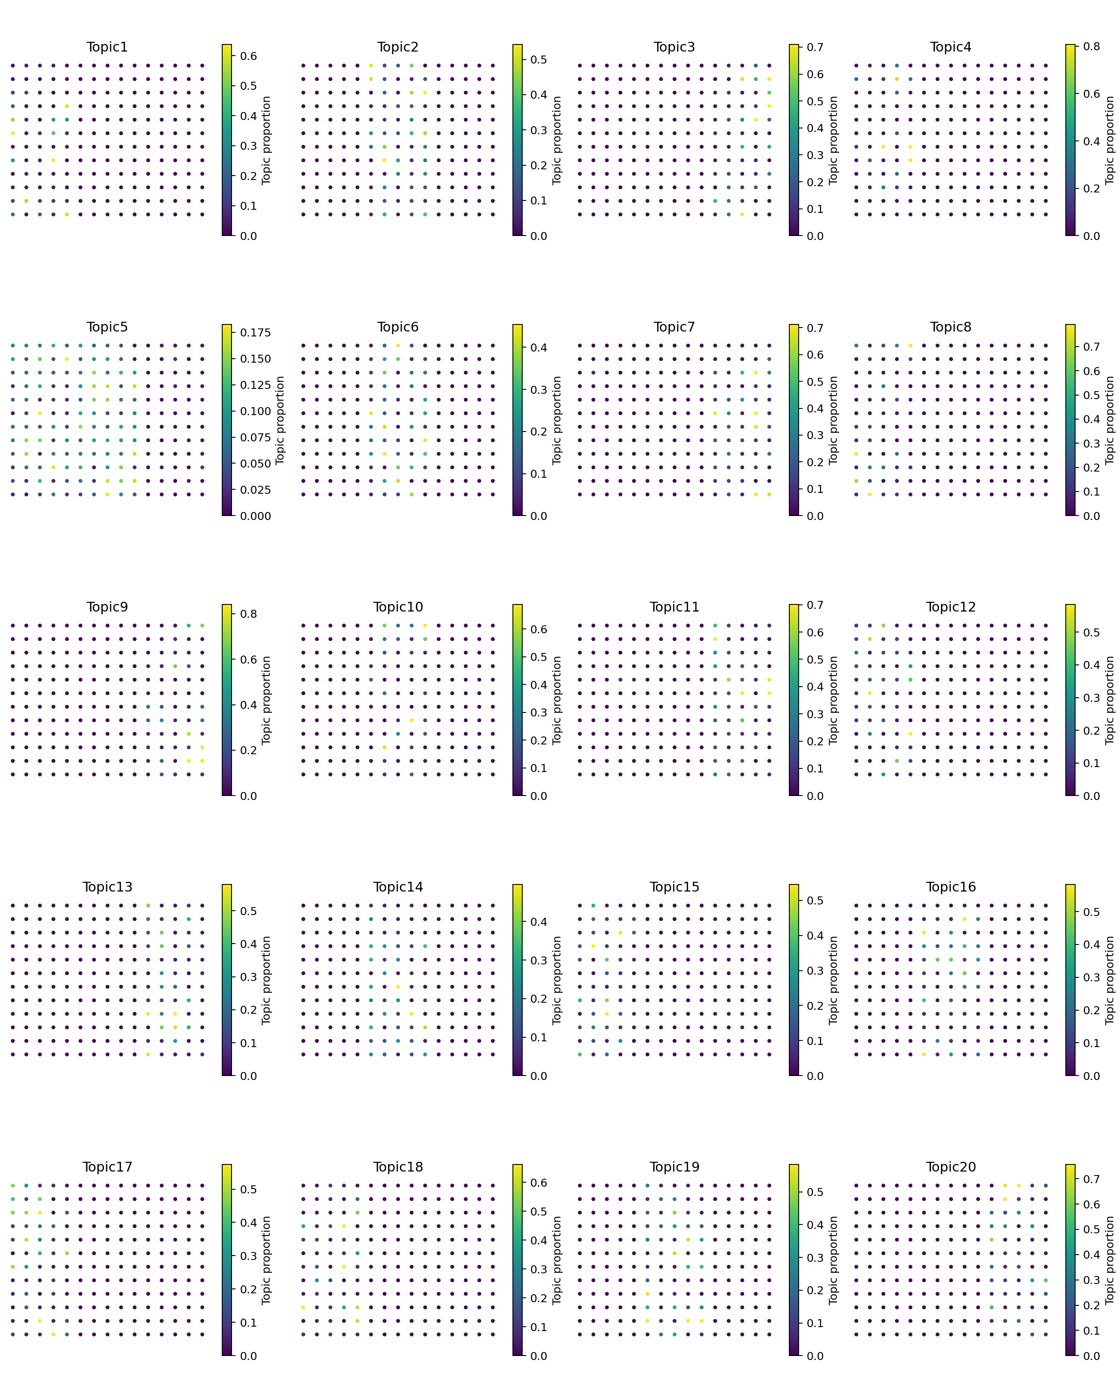

In [7]:
show_panel("cell_types")
show_panel("topic_spatial")


## Save and reuse

The directory includes cell_topic.csv.gz, topic_gene.csv.gz, top_genes.csv, topic_summary.csv, run_config.json, an overview README, and figures. The full matrices preserve identifiers.

In [8]:
print("Saved under:", output)
display(result["topic_summary"].head())


Saved under: outputs\quickstart


,topic,mean_proportion,dominant_cells,top_genes
0,Topic1,0.042746,9,"gene_16, gene_10, gene_18, gene_25, gene_15, gene_2, gene_20, gene_1, gene_13, gene_3"
1,Topic2,0.058448,11,"gene_45, gene_46, gene_41, gene_49, gene_57, gene_53, gene_50, gene_36, gene_47, gene_34"
2,Topic3,0.055981,13,"gene_76, gene_82, gene_81, gene_77, gene_85, gene_70, gene_80, gene_63, gene_87, gene_83"
3,Topic4,0.036995,6,"gene_7, gene_28, gene_12, gene_10, gene_1, gene_29, gene_16, gene_15, gene_8, gene_14"
4,Topic5,0.052860,0,"gene_15, gene_6, gene_0, gene_1, gene_8, gene_18, gene_9, gene_25, gene_22, gene_26"
